# Project overview and data audit

Audits local datasets, labels, missingness, model artifacts, and evaluation readiness using observed files.

No notebook retrains a model. Missing inputs are reported as unavailable.

## Dataset inventory and model artifacts

The disease Training.csv includes an all-null `Unnamed: 133` column (4,920 nulls); the production loader drops `Unnamed:` columns. The dataset also contains 4,616 duplicate full rows, so raw row count overstates unique observations.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src').is_dir() and (p/'data').is_dir())
sys.path.insert(0,str(ROOT)); sys.path.insert(0,str(ROOT/'results'))
from utils.evaluation import setup,save,meta
ROOT=setup(ROOT); OUT=ROOT/'results'
import pandas as pd, matplotlib.pyplot as plt
paths={'disease train':ROOT/'data/disease_prediction/Training.csv','disease test':ROOT/'data/disease_prediction/Testing.csv','NER train':ROOT/'data/ner/splits/ner_train.csv','NER validation':ROOT/'data/ner/splits/ner_validation.csv','NER test':ROOT/'data/ner/splits/ner_test.csv','summary train':ROOT/'data/summarization/processed/train.csv','summary validation':ROOT/'data/summarization/processed/validation.csv','summary test':ROOT/'data/summarization/processed/test.csv'}
rows=[]
for name,p in paths.items():
 if p.exists():
  d=pd.read_csv(p); rows.append({'dataset':name,'path':str(p.relative_to(ROOT)),'rows':len(d),'columns':len(d.columns),'missing':int(d.isna().sum().sum()),'duplicates':int(d.duplicated().sum())})
 else: rows.append({'dataset':name,'path':str(p.relative_to(ROOT)),'rows':None,'columns':None,'missing':None,'duplicates':None})
aud=pd.DataFrame(rows); display(aud); aud.to_csv(OUT/'tables/data_inventory.csv',index=False)
for name,p in [('Fracture CNN',ROOT/'models/bone_fracture_detection/fracture_cnn.keras'),('Disease model',ROOT/'models/disease_prediction/disease_model.keras'),('NER',ROOT/'models/ner/symptom_ner_model'),('BART',ROOT/'models/summarization/checkpoint-68658')]: print(name, 'AVAILABLE' if p.exists() else 'MISSING',p)


,dataset,path,rows,columns,missing,duplicates
0,disease train,data\disease_prediction\Training.csv,4920.0,134.0,4920.0,4616.0
1,disease test,data\disease_prediction\Testing.csv,42.0,133.0,0.0,0.0
2,NER train,data\ner\splits\ner_train.csv,3547.0,6.0,0.0,0.0
3,NER validation,data\ner\splits\ner_validation.csv,116.0,6.0,0.0,0.0
4,NER test,data\ner\splits\ner_test.csv,116.0,6.0,0.0,0.0
5,summary train,data\summarization\processed\train.csv,NaN,NaN,NaN,NaN
6,summary validation,data\summarization\processed\validation.csv,NaN,NaN,NaN,NaN
7,summary test,data\summarization\processed\test.csv,NaN,NaN,NaN,NaN


Fracture CNN AVAILABLE D:\DevLab\Projects\CDSS_Final\models\bone_fracture_detection\fracture_cnn.keras
Disease model AVAILABLE D:\DevLab\Projects\CDSS_Final\models\disease_prediction\disease_model.keras
NER AVAILABLE D:\DevLab\Projects\CDSS_Final\models\ner\symptom_ner_model
BART AVAILABLE D:\DevLab\Projects\CDSS_Final\models\summarization\checkpoint-68658


## Class distributions and pipeline

Fracture counts are directory-based. Existing handoff notes identify byte-identical images across train/test; those metrics do not represent independent generalization. Summarization split files are currently absent.

,split,class,count
0,train,fractured,4606
1,train,not fractured,4640
2,val,fractured,337
3,val,not fractured,492
4,test,fractured,238
5,test,not fractured,268


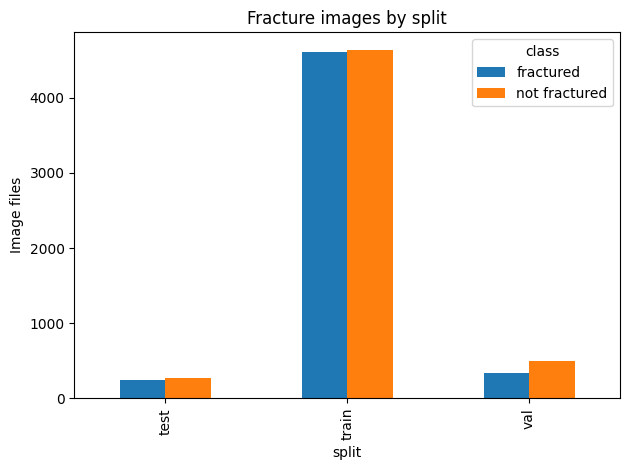

NER columns ['text', 'mentions', 'status', 'tokens', 'labels', 'source'] n= 3547 sources {'template': 2619, 'annotated': 928}


```mermaid
flowchart LR
T[Patient text]-->N[Transformer NER]-->S[Symptom normalization]-->D[Disease classifier]-->R[Recommendation lookups]
F[Findings]-->B[BART summarizer]
X[X-ray]-->C[Fracture CNN]
```

In [2]:
import pandas as pd, matplotlib.pyplot as plt
base=ROOT/'data/xray-fracture/Bone_Fracture_Binary_Classification'; rows=[]
for split in ['train','val','test']:
 for cls in ['fractured','not fractured']:
  p=base/split/cls; rows.append({'split':split,'class':cls,'count':len(list(p.glob('*'))) if p.exists() else 0})
x=pd.DataFrame(rows); display(x); x.to_csv(OUT/'tables/fracture_split_counts.csv',index=False)
x.pivot(index='split',columns='class',values='count').plot.bar(title='Fracture images by split',ylabel='Image files');plt.tight_layout();plt.savefig(OUT/'figures/fracture_class_counts.png',dpi=150);plt.show()
ner=pd.read_csv(ROOT/'data/ner/splits/ner_train.csv'); print('NER columns',ner.columns.tolist(),'n=',len(ner),'sources',ner.get('source',pd.Series(dtype=str)).value_counts().to_dict())
from IPython.display import Markdown,display
display(Markdown('```mermaid\nflowchart LR\nT[Patient text]-->N[Transformer NER]-->S[Symptom normalization]-->D[Disease classifier]-->R[Recommendation lookups]\nF[Findings]-->B[BART summarizer]\nX[X-ray]-->C[Fracture CNN]\n```'))
